## Orange diseases prediction

#### Set up

In [2]:
import os
import random
import numpy as np
import torch
import torch.nn as nn
import json
import shutil
import torchvision.models as models
import torch.optim as optim
import matplotlib.pyplot as plt

from torchvision import transforms
from torch.utils.data import DataLoader
from torch.utils.data import Dataset
from PIL import Image
from torchvision.datasets import ImageFolder

#### EDA

(800, 800)


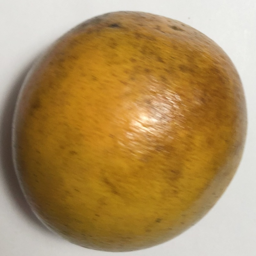

In [3]:
# Open sample images. BLACKSPOT

img_blackspot = Image.open('../data/train/blackspot/b (1).jpg')
print(img_blackspot.size)
img_blackspot.resize((256, 256))

(800, 800)


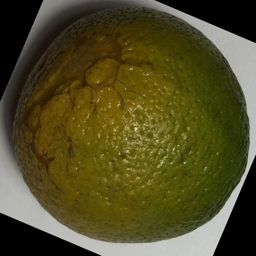

In [4]:
# Open sample images. CANKER

img_canker = Image.open('../data/train/canker/c (1).jpg')
print(img_canker.size)
img_canker.resize((256, 256))

(296, 234)


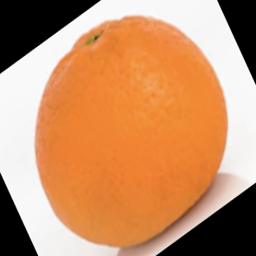

In [5]:
# Open sample images. HEALTHY

img_fresh = Image.open('../data/train/fresh/f (1).png')
print(img_fresh.size)
img_fresh.resize((256, 256))

(800, 800)


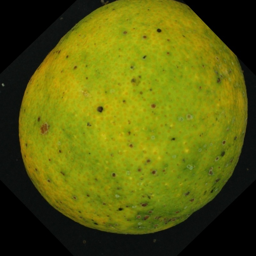

In [6]:
# Open sample images. GREENING

img_grenning = Image.open('../data/train/grenning/g (1).jpg')
print(img_grenning.size)
img_grenning.resize((256, 256))

#### Balance

In [20]:
random.seed(42)

def get_classes(base_path):
    train_path = os.path.join(base_path, 'train')
    if not os.path.exists(train_path):
        print(f"Error: folder not found {train_path}")
        return []
    classes = sorted([d for d in os.listdir(train_path) if os.path.isdir(os.path.join(train_path, d))])
    return classes

classes = get_classes('../data')
print(f'Clases are: {classes}')


def balance_and_copy_dataset(source_base, output_base='../data_reduced', target_train=179, target_test=22):
    categories = get_classes(source_base)
    for split, target in [('train', target_train), ('test', target_test)]:
        source_split_path = os.path.join(source_base, split)
        if not os.path.exists(source_split_path): 
            print(f"Error: root folder not found {source_split_path}")
            continue
        for category in categories:
            source_cat_path = os.path.join(source_split_path, category)
            if not os.path.isdir(source_cat_path): continue
            # Get images
            images = [f for f in os.listdir(source_cat_path) if f.lower().endswith(('.png', '.jpg', '.jpeg'))]
            # Create new folders (ej: ../data_reduced/train/blackspot)
            dest_cat_path = os.path.join(output_base, split, category)
            os.makedirs(dest_cat_path, exist_ok=True)
            # Select images to save
            if len(images) > target:
                print(f" -> [{split.upper()}] Sampling '{category}': copying {target} out of {len(images)} images...")
                images_to_copy = random.sample(images, target)
            else:
                print(f" -> [{split.upper()}] '{category}' has {len(images)} images (copying all, no reduction needed).")
                images_to_copy = images
            # Copy files to new location
            for img in images_to_copy:
                source_file = os.path.join(source_cat_path, img)
                dest_file = os.path.join(dest_cat_path, img)
                shutil.copy(source_file, dest_file)    
    print(f"\n¡Success! New dataset is in: {output_base}")

balance_and_copy_dataset('../data', '../data_reduced')


Clases are: ['blackspot', 'canker', 'fresh', 'grenning']
 -> [TRAIN] Sampling 'blackspot': copying 179 out of 184 images...
 -> [TRAIN] 'canker' has 179 images (copying all, no reduction needed).
 -> [TRAIN] Sampling 'fresh': copying 179 out of 281 images...
 -> [TRAIN] Sampling 'grenning': copying 179 out of 347 images...
 -> [TEST] 'blackspot' has 22 images (copying all, no reduction needed).
 -> [TEST] 'canker' has 22 images (copying all, no reduction needed).
 -> [TEST] Sampling 'fresh': copying 22 out of 33 images...
 -> [TEST] 'grenning' has 22 images (copying all, no reduction needed).

¡Success! New dataset is in: ../data_reduced


#### Base model

In [7]:
SEED = 42
NUM_WORKERS = 0
INPUT_SIZE = 224
MEAN = [0.485, 0.456, 0.406]
STD = [0.229, 0.224, 0.225]
TRAIN_PATH = '../data_reduced/train'
EVALUATION_PATH = '../data_reduced/test'

os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.use_deterministic_algorithms(True)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
device = torch.device("cpu")

In [8]:
train_transform = transforms.Compose([
    transforms.Resize((INPUT_SIZE, INPUT_SIZE), interpolation=transforms.InterpolationMode.NEAREST),
    transforms.ToTensor(),
    transforms.Normalize(mean=MEAN, std=STD),
])

evaluation_transform = transforms.Compose([
    transforms.Resize((INPUT_SIZE, INPUT_SIZE), interpolation=transforms.InterpolationMode.NEAREST),
    transforms.ToTensor(),
    transforms.Normalize(mean=MEAN, std=STD),
])

train_dataset = ImageFolder(TRAIN_PATH, transform=train_transform)
evaluation_dataset = ImageFolder(EVALUATION_PATH, transform=evaluation_transform)

def seed_worker(worker_id):
    worker_seed = torch.initial_seed() % 2**32
    np.random.seed(worker_seed)
    random.seed(worker_seed)

loader_generator = torch.Generator().manual_seed(SEED)

train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True,
    num_workers=NUM_WORKERS,
    worker_init_fn=seed_worker,
    generator=loader_generator
)

evaluation_loader = DataLoader(
    evaluation_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=NUM_WORKERS
)

In [9]:
class OrangeDiseasesClassifierOriginal(nn.Module):
    def __init__(self, droprate=0.2, num_classes=4): # Cambiado por defecto a 4 para tus naranjas
        super(OrangeDiseasesClassifierOriginal, self).__init__()
        # 1. Load pre-trained MobileNetV2
        self.base_model = models.mobilenet_v2(weights='IMAGENET1K_V1')
        # 2. Freeze base model parameters
        for param in self.base_model.parameters():
            param.requires_grad = False
        # 3. Remove original classifier
        self.base_model.classifier = nn.Identity()
        # 4. Capas personalizadas (Flujo original de MobileNetV2)
        self.global_avg_pooling = nn.AdaptiveAvgPool2d((1, 1))
        self.dropout = nn.Dropout(p=droprate)
        self.output_layer = nn.Linear(1280, num_classes) # Directo de 1280 a tus clases

    def forward(self, x):
        x = self.base_model.features(x)
        x = self.global_avg_pooling(x)
        x = torch.flatten(x, 1)
        x = self.dropout(x)
        x = self.output_layer(x)
        return x


In [10]:
def train_and_evaluate(model, optimizer, train_loader, evaluation_loader, criterion, num_epochs, device, version):
    best_evaluation_accuracy = 0.0
    history = {'train_loss': [], 'train_accuracy': [], 'evaluation_loss': [], 'evaluation_accuracy': []}
    for epoch in range(num_epochs):
        # Training phase
        model.train() # Set the model to training phase
        running_loss = 0.0
        correct = 0
        total = 0
        for inputs, labels in train_loader:
            inputs = inputs.to(device)
            labels = labels.to(device)
            optimizer.zero_grad() # Deletes gradients calculated in last step
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            running_loss += loss.item()
            _, predicted = torch.max(outputs.data, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()
        train_loss = running_loss / len(train_loader)
        train_accuracy = correct / total
        history['train_loss'].append(train_loss)
        history['train_accuracy'].append(train_accuracy)
        # Evaluation phase
        model.eval() # Set the model to evaluation phase
        evaluation_loss = 0.0
        evaluation_correct = 0
        evaluation_total = 0
        with torch.no_grad(): # No gradient calculation
            for inputs, labels in evaluation_loader:
                inputs = inputs.to(device)
                labels = labels.to(device)
                outputs = model(inputs)
                loss = criterion(outputs, labels)
                evaluation_loss += loss.item()
                _, predicted = torch.max(outputs.data, 1)
                evaluation_total += labels.size(0)
                evaluation_correct += (predicted == labels).sum().item()
        evaluation_loss /= len(evaluation_loader)
        evaluation_accuracy = evaluation_correct / evaluation_total
        history['evaluation_loss'].append(evaluation_loss)
        history['evaluation_accuracy'].append(evaluation_accuracy)
        # Print and save results
        print(f'Epoch {epoch+1}/{num_epochs}')
        print(f'  Train Loss: {train_loss:.4f}, Train Acc: {train_accuracy:.4f}')
        print(f'  Eval Loss: {evaluation_loss:.4f}, Eval Acc: {evaluation_accuracy:.4f}')
        if evaluation_accuracy > best_evaluation_accuracy:
            best_evaluation_accuracy = evaluation_accuracy
            checkpoint_path = f'../results/v{version}_{epoch+1:02d}_{evaluation_accuracy:.3f}.pth'
            torch.save(model.state_dict(), checkpoint_path)
            print(f'Saved: {checkpoint_path}')
    return history

In [14]:
# Train model base
NUM_EPOCHS = 10

model = OrangeDiseasesClassifierOriginal(num_classes=4)
model.to(device)
optimizer = optim.Adam(
    filter(lambda p: p.requires_grad, model.parameters()), 
    lr=0.01
)
criterion = nn.CrossEntropyLoss()

history0 = train_and_evaluate(model, optimizer, train_loader, evaluation_loader, criterion, NUM_EPOCHS, device, '0')

Epoch 1/10
  Train Loss: 0.5582, Train Acc: 0.8128
  Eval Loss: 0.1543, Eval Acc: 0.9318
Saved: ../results/v0_01_0.932.pth
Epoch 2/10
  Train Loss: 0.1415, Train Acc: 0.9427
  Eval Loss: 0.1155, Eval Acc: 0.9545
Saved: ../results/v0_02_0.955.pth
Epoch 3/10
  Train Loss: 0.0657, Train Acc: 0.9804
  Eval Loss: 0.1254, Eval Acc: 0.9545
Epoch 4/10
  Train Loss: 0.0578, Train Acc: 0.9763
  Eval Loss: 0.1497, Eval Acc: 0.9545
Epoch 5/10
  Train Loss: 0.0584, Train Acc: 0.9763
  Eval Loss: 0.1467, Eval Acc: 0.9659
Saved: ../results/v0_05_0.966.pth
Epoch 6/10
  Train Loss: 0.1008, Train Acc: 0.9665
  Eval Loss: 0.1339, Eval Acc: 0.9659
Epoch 7/10
  Train Loss: 0.1077, Train Acc: 0.9665
  Eval Loss: 0.1679, Eval Acc: 0.9659
Epoch 8/10
  Train Loss: 0.0269, Train Acc: 0.9916
  Eval Loss: 0.1204, Eval Acc: 0.9659
Epoch 9/10
  Train Loss: 0.0547, Train Acc: 0.9777
  Eval Loss: 0.1549, Eval Acc: 0.9659
Epoch 10/10
  Train Loss: 0.0447, Train Acc: 0.9832
  Eval Loss: 0.3425, Eval Acc: 0.9091


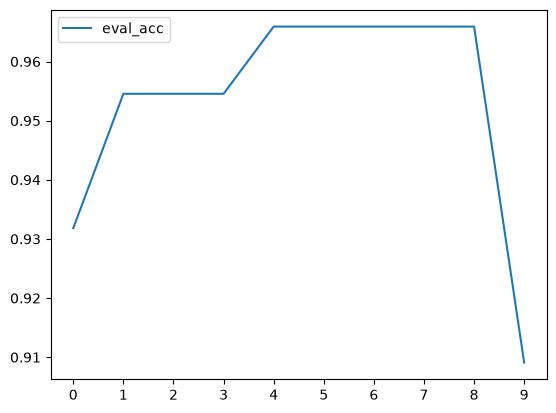

In [15]:
plt.plot(history0['evaluation_accuracy'], label='eval_acc')
plt.xticks(np.arange(10))
plt.legend()

#### Hyperparameter tunning

In [11]:
class OrangeDiseasesClassifierImproved(nn.Module):
    def __init__(self, size_inner=100, droprate=0.2, num_classes=4):
        super(OrangeDiseasesClassifierImproved, self).__init__()
        # Load pre-trained MobileNetV2
        self.base_model = models.mobilenet_v2(weights='IMAGENET1K_V1')
        # Freeze base model parameters
        for param in self.base_model.parameters():
            param.requires_grad = False
        # Remove original classifier
        self.base_model.classifier = nn.Identity()
        # Add custom layers
        self.global_avg_pooling = nn.AdaptiveAvgPool2d((1, 1))
        self.inner = nn.Linear(1280, size_inner)  # New inner layer
        self.relu = nn.ReLU()
        self.dropout = nn.Dropout(droprate)  # Add dropout
        self.output_layer = nn.Linear(size_inner, num_classes)

    def forward(self, x):
        x = self.base_model.features(x)
        x = self.global_avg_pooling(x)
        x = torch.flatten(x, 1)
        x = self.inner(x)
        x = self.relu(x)
        x = self.dropout(x)  # Apply dropout
        x = self.output_layer(x)
        return x

def make_model(learning_rate = 0.01, size_inner=100, droprate=0.2):
    model = OrangeDiseasesClassifierImproved(size_inner=size_inner, droprate=droprate, num_classes=4)
    model.to(device)
    optimizer = optim.Adam(
        filter(lambda p: p.requires_grad, model.parameters()), 
        lr=learning_rate
    )
    return model, optimizer


##### Tunning learning rate

In [ ]:
criterion = nn.CrossEntropyLoss()
learning_rates = [0.0001, 0.001, 0.01]
history1 = []
size_inner = 100
droprate = 0.2
for lr in learning_rates:
    print(f'Learning rate: {lr}')
    inner_model, inner_optimizer = make_model(lr, size_inner, droprate)
    version = f'{lr}-{size_inner}-{droprate}'
    history_inner = train_and_evaluate(
        inner_model, inner_optimizer, train_loader, evaluation_loader, criterion, NUM_EPOCHS, device, version
    )
    history1.append(history_inner)

Learning rate: 0.0001
Epoch 1/10
  Train Loss: 1.1540, Train Acc: 0.6885
  Eval Loss: 0.9066, Eval Acc: 0.9205
Saved: ../results/v0.0001-100-0.2_01_0.920.pth
Epoch 2/10
  Train Loss: 0.7628, Train Acc: 0.8966
  Eval Loss: 0.5614, Eval Acc: 0.9432
Saved: ../results/v0.0001-100-0.2_02_0.943.pth
Epoch 3/10
  Train Loss: 0.5008, Train Acc: 0.9427
  Eval Loss: 0.3966, Eval Acc: 0.9091
Epoch 4/10
  Train Loss: 0.3870, Train Acc: 0.9413
  Eval Loss: 0.3079, Eval Acc: 0.9545
Saved: ../results/v0.0001-100-0.2_04_0.955.pth
Epoch 5/10
  Train Loss: 0.3203, Train Acc: 0.9525
  Eval Loss: 0.2555, Eval Acc: 0.9545
Epoch 6/10
  Train Loss: 0.2428, Train Acc: 0.9735
  Eval Loss: 0.2206, Eval Acc: 0.9432
Epoch 7/10
  Train Loss: 0.2104, Train Acc: 0.9749
  Eval Loss: 0.1959, Eval Acc: 0.9432
Epoch 8/10
  Train Loss: 0.1813, Train Acc: 0.9693
  Eval Loss: 0.1772, Eval Acc: 0.9545
Epoch 9/10
  Train Loss: 0.1789, Train Acc: 0.9721
  Eval Loss: 0.1616, Eval Acc: 0.9432
Epoch 10/10
  Train Loss: 0.1426, Tr

KeyError: 'eval_acc'

<Figure size 1000x600 with 0 Axes>

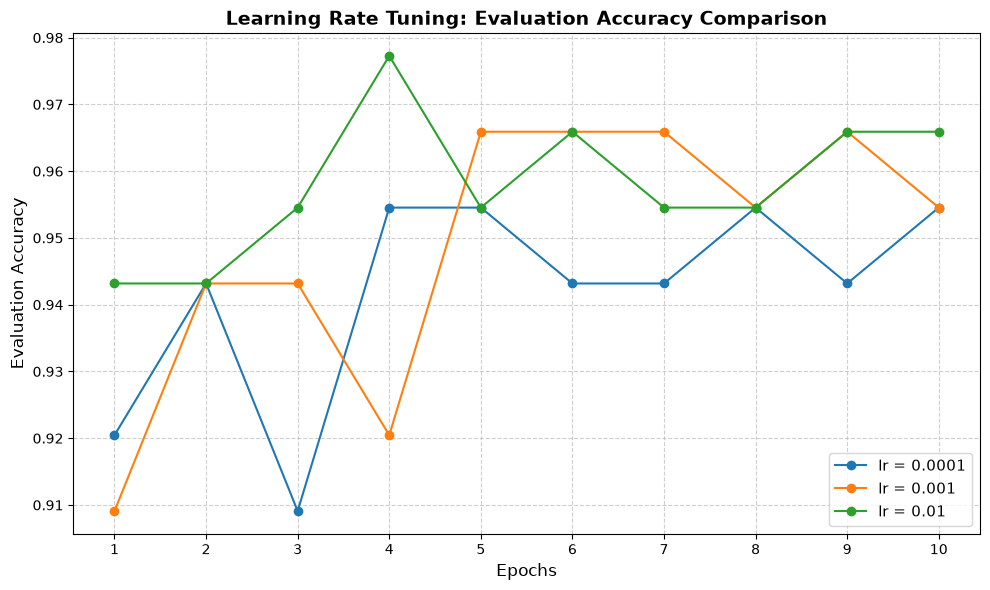

In [30]:
plt.figure(figsize=(10, 6))
for lr, history in zip(learning_rates, history1):
    epochs = range(1, len(history['evaluation_accuracy']) + 1)
    plt.plot(epochs, history['evaluation_accuracy'], marker='o', label=f'lr = {lr}')
plt.title('Learning Rate Tuning: Evaluation Accuracy Comparison', fontsize=14, fontweight='bold')
plt.xlabel('Epochs', fontsize=12)
plt.ylabel('Evaluation Accuracy', fontsize=12)
plt.xticks(epochs) 
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(fontsize=11, loc='lower right')
plt.tight_layout()
plt.show()

In [12]:
learning_rate_selected = 0.01
print(f'learning rate selected: {learning_rate_selected}')

learning rate selected: 0.01


##### Tunning size of inner layer

In [16]:
criterion = nn.CrossEntropyLoss()
sizes = [10, 100, 1000]
history2 = []
droprate = 0.2
for size_inner in sizes:
    print(f'size inner: {size_inner}')
    inner_model, inner_optimizer = make_model(learning_rate_selected, size_inner, droprate)
    version = f'{learning_rate_selected}-{size_inner}-{droprate}'
    history_inner = train_and_evaluate(
        inner_model, inner_optimizer, train_loader, evaluation_loader, criterion, NUM_EPOCHS, device, version
    )
    history2.append(history_inner)

size inner: 10
Epoch 1/10
  Train Loss: 1.0758, Train Acc: 0.6327
  Eval Loss: 0.2737, Eval Acc: 0.9432
Saved: ../results/v0.01-10-0.2_01_0.943.pth
Epoch 2/10
  Train Loss: 0.3652, Train Acc: 0.8422
  Eval Loss: 0.1432, Eval Acc: 0.9659
Saved: ../results/v0.01-10-0.2_02_0.966.pth
Epoch 3/10
  Train Loss: 0.2844, Train Acc: 0.8883
  Eval Loss: 0.1366, Eval Acc: 0.9659
Epoch 4/10
  Train Loss: 0.2908, Train Acc: 0.8911
  Eval Loss: 0.1204, Eval Acc: 0.9659
Epoch 5/10
  Train Loss: 0.2909, Train Acc: 0.8994
  Eval Loss: 0.1119, Eval Acc: 0.9659
Epoch 6/10
  Train Loss: 0.2516, Train Acc: 0.9148
  Eval Loss: 0.0989, Eval Acc: 0.9659
Epoch 7/10
  Train Loss: 0.2169, Train Acc: 0.9106
  Eval Loss: 0.1084, Eval Acc: 0.9659
Epoch 8/10
  Train Loss: 0.2139, Train Acc: 0.9218
  Eval Loss: 0.1158, Eval Acc: 0.9432
Epoch 9/10
  Train Loss: 0.2261, Train Acc: 0.9218
  Eval Loss: 0.0995, Eval Acc: 0.9659
Epoch 10/10
  Train Loss: 0.2058, Train Acc: 0.9204
  Eval Loss: 0.1015, Eval Acc: 0.9659
size i

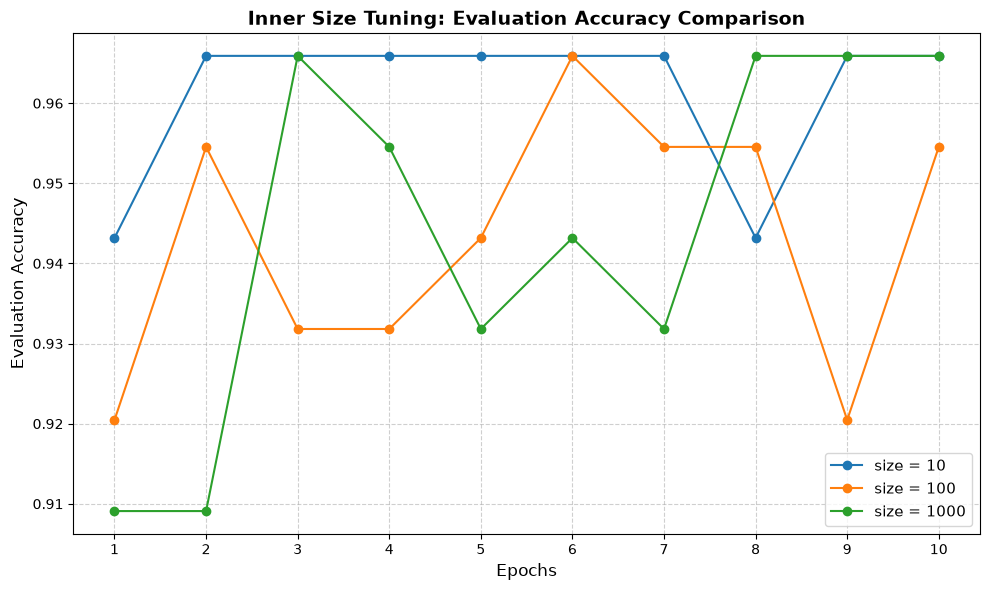

In [17]:
plt.figure(figsize=(10, 6))
for size, history in zip(sizes, history2):
    epochs = range(1, len(history['evaluation_accuracy']) + 1)
    plt.plot(epochs, history['evaluation_accuracy'], marker='o', label=f'size = {size}')
plt.title('Inner Size Tuning: Evaluation Accuracy Comparison', fontsize=14, fontweight='bold')
plt.xlabel('Epochs', fontsize=12)
plt.ylabel('Evaluation Accuracy', fontsize=12)
plt.xticks(epochs) 
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(fontsize=11, loc='lower right')
plt.tight_layout()
plt.show()

In [19]:
size_inner_selected = 10
print(f'size_inner selected: {size_inner_selected}')

size_inner selected: 10


##### Tunning dropout rate

In [20]:
criterion = nn.CrossEntropyLoss()
dropouts = [0.0, 0.2, 0.5]
history3 = []
for dropout in dropouts:
    print(f'dropout: {dropout}')
    inner_model, inner_optimizer = make_model(learning_rate_selected, size_inner_selected, dropout)
    version = f'{learning_rate_selected}-{size_inner_selected}-{dropout}'
    history_inner = train_and_evaluate(
        inner_model, inner_optimizer, train_loader, evaluation_loader, criterion, NUM_EPOCHS, device, version
    )
    history3.append(history_inner)

dropout: 0.0
Epoch 1/10
  Train Loss: 0.4933, Train Acc: 0.7709
  Eval Loss: 0.1574, Eval Acc: 0.9545
Saved: ../results/v0.01-10-0.0_01_0.955.pth
Epoch 2/10
  Train Loss: 0.2000, Train Acc: 0.9274
  Eval Loss: 0.1158, Eval Acc: 0.9659
Saved: ../results/v0.01-10-0.0_02_0.966.pth
Epoch 3/10
  Train Loss: 0.0912, Train Acc: 0.9763
  Eval Loss: 0.1280, Eval Acc: 0.9318
Epoch 4/10
  Train Loss: 0.0655, Train Acc: 0.9818
  Eval Loss: 0.1606, Eval Acc: 0.9432
Epoch 5/10
  Train Loss: 0.0525, Train Acc: 0.9791
  Eval Loss: 0.1236, Eval Acc: 0.9659
Epoch 6/10
  Train Loss: 0.0447, Train Acc: 0.9846
  Eval Loss: 0.1239, Eval Acc: 0.9659
Epoch 7/10
  Train Loss: 0.0567, Train Acc: 0.9791
  Eval Loss: 0.1523, Eval Acc: 0.9545
Epoch 8/10
  Train Loss: 0.0548, Train Acc: 0.9804
  Eval Loss: 0.2324, Eval Acc: 0.9091
Epoch 9/10
  Train Loss: 0.0427, Train Acc: 0.9874
  Eval Loss: 0.1897, Eval Acc: 0.9432
Epoch 10/10
  Train Loss: 0.0544, Train Acc: 0.9763
  Eval Loss: 0.1360, Eval Acc: 0.9773
Saved: .

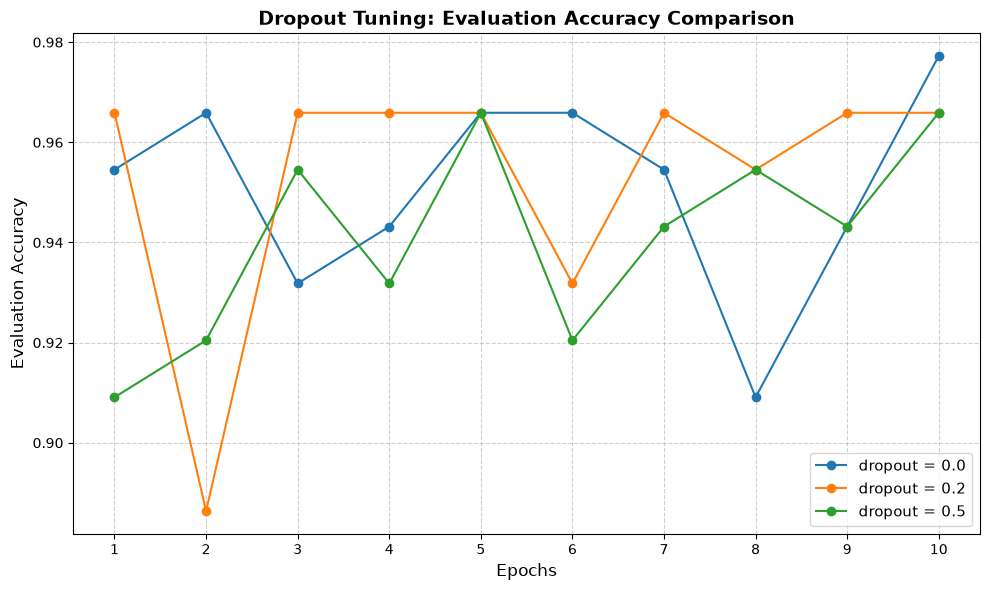

In [22]:
plt.figure(figsize=(10, 6))
for dropout, history in zip(dropouts, history3):
    epochs = range(1, len(history['evaluation_accuracy']) + 1)
    plt.plot(epochs, history['evaluation_accuracy'], marker='o', label=f'dropout = {dropout}')
plt.title('Dropout Tuning: Evaluation Accuracy Comparison', fontsize=14, fontweight='bold')
plt.xlabel('Epochs', fontsize=12)
plt.ylabel('Evaluation Accuracy', fontsize=12)
plt.xticks(epochs) 
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(fontsize=11, loc='lower right')
plt.tight_layout()
plt.show()

In [23]:
dropout_selected = 0.02
print(f'dropout_selected: {dropout_selected}')

dropout_selected: 0.02


##### Data augmentation

In [24]:
train_transform = transforms.Compose([
    transforms.Resize((INPUT_SIZE, INPUT_SIZE), interpolation=transforms.InterpolationMode.NEAREST),
    transforms.RandomRotation(10), # Rotate up to 10 degrees
    transforms.RandomResizedCrop(INPUT_SIZE, scale=(0.9, 1.0)), # Zoom
    transforms.RandomHorizontalFlip(), # Horizontal flip
    transforms.ToTensor(),
    transforms.Normalize(mean=MEAN, std=STD),
])

evaluation_transform = transforms.Compose([
    transforms.Resize((INPUT_SIZE, INPUT_SIZE), interpolation=transforms.InterpolationMode.NEAREST),
    transforms.ToTensor(),
    transforms.Normalize(mean=MEAN, std=STD),
])

train_dataset = ImageFolder(TRAIN_PATH, transform=train_transform)
evaluation_dataset = ImageFolder(EVALUATION_PATH, transform=evaluation_transform)

def seed_worker(worker_id):
    worker_seed = torch.initial_seed() % 2**32
    np.random.seed(worker_seed)
    random.seed(worker_seed)

loader_generator = torch.Generator().manual_seed(SEED)

train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True,
    num_workers=NUM_WORKERS,
    worker_init_fn=seed_worker,
    generator=loader_generator
)

evaluation_loader = DataLoader(
    evaluation_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=NUM_WORKERS
)

In [26]:
criterion = nn.CrossEntropyLoss()
NUM_EPOCHS = 20
inner_model, inner_optimizer = make_model(learning_rate_selected, size_inner_selected, dropout_selected)
version = f'{learning_rate_selected}-{size_inner_selected}-{dropout_selected}-aug'
history4 = train_and_evaluate(
    inner_model, inner_optimizer, train_loader, evaluation_loader, criterion, NUM_EPOCHS, device, version
)


Epoch 1/20
  Train Loss: 0.8651, Train Acc: 0.6536
  Eval Loss: 0.2163, Eval Acc: 0.9205
Saved: ../results/v0.01-10-0.02-aug_01_0.920.pth
Epoch 2/20
  Train Loss: 0.2761, Train Acc: 0.9064
  Eval Loss: 0.1992, Eval Acc: 0.9318
Saved: ../results/v0.01-10-0.02-aug_02_0.932.pth
Epoch 3/20
  Train Loss: 0.2038, Train Acc: 0.9358
  Eval Loss: 0.1628, Eval Acc: 0.9091
Epoch 4/20
  Train Loss: 0.2396, Train Acc: 0.9176
  Eval Loss: 0.1427, Eval Acc: 0.9318
Epoch 5/20
  Train Loss: 0.1292, Train Acc: 0.9581
  Eval Loss: 0.1227, Eval Acc: 0.9545
Saved: ../results/v0.01-10-0.02-aug_05_0.955.pth
Epoch 6/20
  Train Loss: 0.1205, Train Acc: 0.9609
  Eval Loss: 0.1094, Eval Acc: 0.9432
Epoch 7/20
  Train Loss: 0.0892, Train Acc: 0.9679
  Eval Loss: 0.1119, Eval Acc: 0.9545
Epoch 8/20
  Train Loss: 0.1341, Train Acc: 0.9483
  Eval Loss: 0.1338, Eval Acc: 0.9432
Epoch 9/20
  Train Loss: 0.1405, Train Acc: 0.9623
  Eval Loss: 0.1326, Eval Acc: 0.9545
Epoch 10/20
  Train Loss: 0.1061, Train Acc: 0.9581


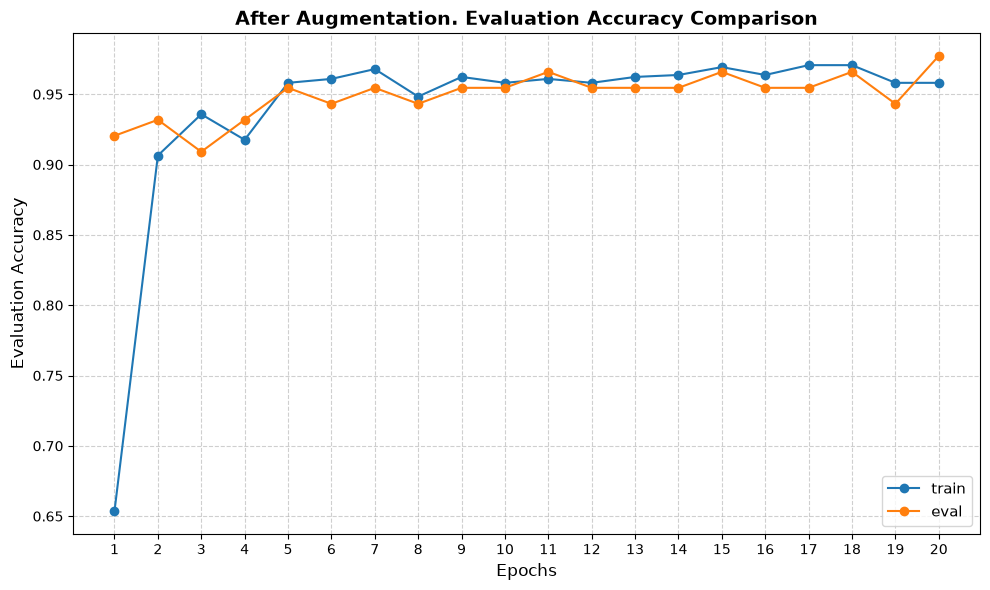

In [28]:
plt.figure(figsize=(10, 6))
epochs = range(1, len(history4['evaluation_accuracy']) + 1)
plt.plot(epochs, history4['train_accuracy'], marker='o', label=f'train')
plt.plot(epochs, history4['evaluation_accuracy'], marker='o', label=f'eval')
plt.title('After Augmentation. Evaluation Accuracy Comparison', fontsize=14, fontweight='bold')
plt.xlabel('Epochs', fontsize=12)
plt.ylabel('Evaluation Accuracy', fontsize=12)
plt.xticks(epochs) 
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(fontsize=11, loc='lower right')
plt.tight_layout()
plt.show()

#### Use the model

In [38]:
classes = ['blackspot', 'canker', 'fresh', 'grenning']
img = Image.open('../examples/example_blakspot.png')
path = '../results/v0.01-10-0.02-aug_20_0.977.pth'
model = OrangeDiseasesClassifierImproved(size_inner=10, droprate=0.2, num_classes=4)
model.load_state_dict(torch.load(path, weights_only=True, map_location=device))
model.to(device)
model.eval()
x=evaluation_transform(img)
batch_t = torch.unsqueeze(x, 0).to(device)
with torch.no_grad():
    logits = model(batch_t)
    probabilities = torch.softmax(logits, dim=1)
probabilities_list = probabilities[0].cpu().tolist()
res = dict(zip(classes, probabilities_list))
print("Predicciones del modelo:")
for clase, prob in res.items():
    print(f"  {clase}: {prob*100:.2f}%")


Predicciones del modelo:
  blackspot: 93.96%
  canker: 0.29%
  fresh: 0.22%
  grenning: 5.54%


#### Save the model

In [42]:
path_pytorch = '../models/v0.01-10-0.02-aug_20_0.977.pth'
model = OrangeDiseasesClassifierImproved(size_inner=10, droprate=0.2, num_classes=4)
model.load_state_dict(torch.load(path_pytorch, weights_only=True, map_location='cpu'))
model.eval()
dummy_input = torch.randn(1, 3, 224, 224)
path_onnx = '../models/orange_diseases_model.onnx'
torch.onnx.export(
    model,
    dummy_input,
    path_onnx,
    input_names=['input'],
    output_names=['output'],
    dynamic_axes={
        'input': {0: 'batch_size'},
        'output': {0: 'batch_size'}
    }
)

print(f"✅ Model exported to ONNX format in: {path_onnx}")

/tmp/ipykernel_913/1871760177.py:7: UserWarning: # 'dynamic_axes' is not recommended when dynamo=True, and may lead to 'torch._dynamo.exc.UserError: Constraints violated.' Supply the 'dynamic_shapes' argument instead if export is unsuccessful.
  torch.onnx.export(


[torch.onnx] Obtain model graph for `OrangeDiseasesClassifierImproved([...]` with `torch.export.export(..., strict=False)`...
[torch.onnx] Obtain model graph for `OrangeDiseasesClassifierImproved([...]` with `torch.export.export(..., strict=False)`... ✅
[torch.onnx] Run decompositions...
[torch.onnx] Run decompositions... ✅
[torch.onnx] Translate the graph into ONNX...
[torch.onnx] Translate the graph into ONNX... ✅
[torch.onnx] Optimize the ONNX graph...
[torch.onnx] Optimize the ONNX graph... ✅
✅ Model exported to ONNX format in: ../models/orange_diseases_model.onnx
